In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DB = Path("..") / "data" / "energy.db"
df = pd.read_sql("SELECT * FROM hourly_usage", sqlite3.connect(DB),
                 parse_dates=["datetime"])

print(df.shape)
print(df["datetime"].min(), "to", df["datetime"].max())
df["kwh"].describe()


(34168, 5)
2006-12-16 17:00:00 to 2010-11-26 21:00:00


count    34168.000000
mean         1.091728
std          0.897619
min          0.124000
25%          0.341925
50%          0.802850
75%          1.579342
max          6.560533
Name: kwh, dtype: float64

FileNotFoundError: [Errno 2] No such file or directory: '../docs/images/hourly_profile.png'

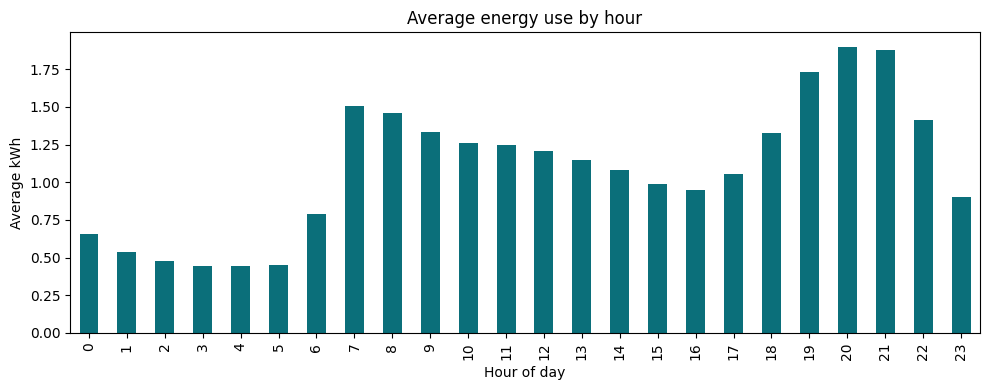

In [2]:
hourly_avg = df.groupby("hour")["kwh"].mean()

ax = hourly_avg.plot(kind="bar", figsize=(10, 4), color="#0b6f7a")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average kWh")
ax.set_title("Average energy use by hour")
plt.tight_layout()
plt.savefig("../docs/images/hourly_profile.png", dpi=150)
plt.show()

print("Busiest hour:", hourly_avg.idxmax(), "->", round(hourly_avg.max(), 2), "kWh")
print("Quietest hour:", hourly_avg.idxmin(), "->", round(hourly_avg.min(), 2), "kWh")

FileNotFoundError: [Errno 2] No such file or directory: '../docs/images/heatmap.png'

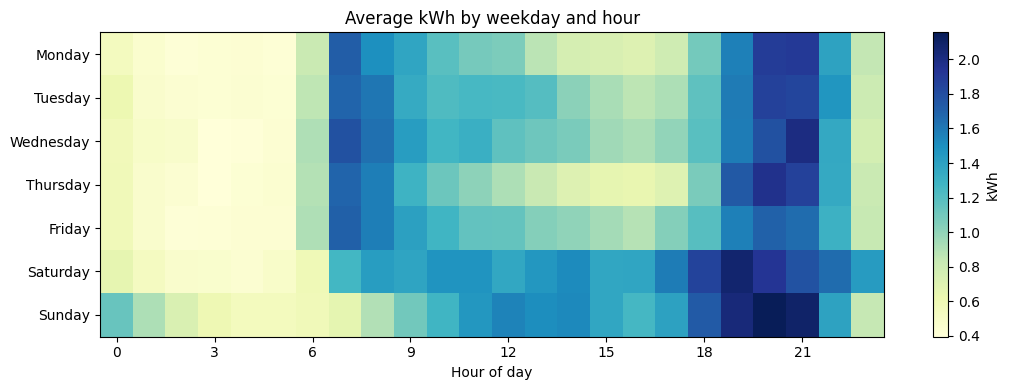

In [3]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (df.pivot_table(index="weekday", columns="hour", values="kwh", aggfunc="mean")
          .reindex(order))

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(7)); ax.set_yticklabels(order)
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.set_title("Average kWh by weekday and hour")
fig.colorbar(im, label="kWh")
plt.tight_layout()
plt.savefig("../docs/images/heatmap.png", dpi=150)
plt.show()

weekend = df[df["weekday"].isin(["Saturday", "Sunday"])]["kwh"].mean()
weekday = df[~df["weekday"].isin(["Saturday", "Sunday"])]["kwh"].mean()
print(f"Weekend use is {(weekend / weekday - 1) * 100:.0f}% different from weekdays")

FileNotFoundError: [Errno 2] No such file or directory: '../docs/images/monthly_trend.png'

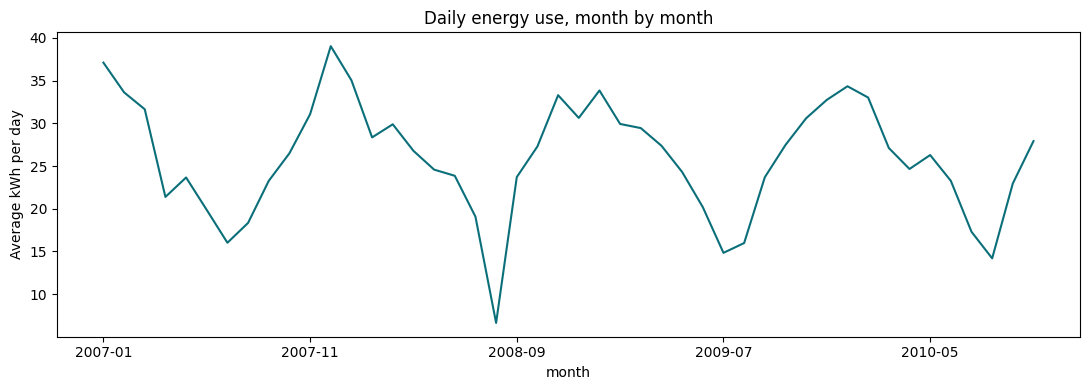

In [4]:
by_month = df.groupby("month")["kwh"].mean() * 24     # kWh per day
by_month = by_month.iloc[1:-1]                         # drop partial first/last month

ax = by_month.plot(figsize=(11, 4), color="#0b6f7a")
ax.set_ylabel("Average kWh per day")
ax.set_title("Daily energy use, month by month")

plt.tight_layout()
plt.savefig("../docs/images/monthly_trend.png", dpi=150)
plt.show()

season = df.groupby(df["datetime"].dt.month)["kwh"].mean() * 24
print("Highest calendar month:", season.idxmax(), round(season.max(), 1), "kWh/day")
print("Lowest calendar month:", season.idxmin(), round(season.min(), 1), "kWh/day")

In [5]:
baseload_per_day = hourly_avg.min() * 24
total_per_day = hourly_avg.sum()
print(f"Baseload: {baseload_per_day:.1f} kWh/day "
      f"({baseload_per_day / total_per_day * 100:.0f}% of daily use)")


Baseload: 10.7 kWh/day (41% of daily use)


In [6]:
price = 0.30                     # € per kWh, change to your own tariff
evening = hourly_avg.loc[18:22].sum()
cut = 0.20                       # cut evening use by 20%

saved_kwh = evening * cut * 365
print(f"Evening share of daily use: {evening / total_per_day * 100:.0f}%")
print(f"Saving per year: {saved_kwh:.0f} kWh = €{saved_kwh * price:.0f}")

Evening share of daily use: 31%
Saving per year: 602 kWh = €181


In [7]:
from pathlib import Path

image_dir = Path("../docs/images")

image_dir.mkdir(parents=True, exist_ok=True)

In [2]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
file_path = "data/household_power_consumption.txt"



In [4]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in current directory:")
print(list(Path.cwd().iterdir()))

print("\nFiles in parent directory's data folder:")
print(list((Path.cwd().parent / "data").glob("*")))

Current working directory:
c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser\notebooks

Files in current directory:
[WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/notebooks/.ipynb_checkpoints'), WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/notebooks/analysis.ipynb')]

Files in parent directory's data folder:
[WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/data/.ipynb_checkpoints'), WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/data/energy.db'), WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/data/Untitled.ipynb')]


In [8]:
from pathlib import Path

# Identify the main project folder
PROJECT_ROOT = Path.cwd().parent

# Raw dataset location
RAW_DATA = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "household_power_consumption.txt"
)

# Processed database location
DB_PATH = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "energy.db"
)

print("Project folder:", PROJECT_ROOT)

print("Raw dataset exists:", RAW_DATA.exists())

print("Database exists:", DB_PATH.exists())

Project folder: c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser
Raw dataset exists: True
Database exists: True


In [9]:
from pathlib import Path

print("CURRENT LOCATION:")
print(Path.cwd())

print("\nCONTENTS OF CURRENT FOLDER:")
print(list(Path.cwd().iterdir()))

print("\nSEARCHING FOR RAW DATASET:")

for file in Path.cwd().parent.rglob("household_power_consumption*"):
    print(file)

CURRENT LOCATION:
c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser\notebooks

CONTENTS OF CURRENT FOLDER:
[WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/notebooks/.ipynb_checkpoints'), WindowsPath('c:/Users/AshishKaur/OneDrive/Desktop/enery-usage-analyser/notebooks/analysis.ipynb')]

SEARCHING FOR RAW DATASET:
c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser\data\raw\household_power_consumption.txt


In [10]:
from pathlib import Path

# Locate the main project folder
current = Path.cwd()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "src").is_dir()
        and (p / "README.md").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder could not be located.")

RAW_DATA = PROJECT_ROOT / "data" / "raw" / "household_power_consumption.txt"

DB_PATH = PROJECT_ROOT / "data" / "processed" / "energy.db"

print("PROJECT:", PROJECT_ROOT)
print("RAW DATA EXISTS:", RAW_DATA.exists())
print("DATABASE EXISTS:", DB_PATH.exists())


PROJECT: c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser
RAW DATA EXISTS: True
DATABASE EXISTS: True


In [11]:
import sqlite3
import pandas as pd

# Connect to our database
conn = sqlite3.connect(DB_PATH)

# Find all tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)

print("DATABASE TABLES:")
display(tables)


DATABASE TABLES:


,name
0,hourly_usage


In [12]:
schema = pd.read_sql_query(
    "PRAGMA table_info(hourly_usage)",
    conn
)

display(schema)

,cid,name,type,notnull,dflt_value,pk
0,0,datetime,TIMESTAMP,0,None,0
1,1,kwh,REAL,0,None,0
2,2,hour,INTEGER,0,None,0
3,3,weekday,TEXT,0,None,0
4,4,month,TEXT,0,None,0


In [13]:
df = pd.read_sql_query(
    "SELECT * FROM hourly_usage LIMIT 10",
    conn,
    parse_dates=["datetime"]
)

display(df)

,datetime,kwh,hour,weekday,month
0,2006-12-16 17:00:00,4.222889,17,Saturday,2006-12
1,2006-12-16 18:00:00,3.632200,18,Saturday,2006-12
2,2006-12-16 19:00:00,3.400233,19,Saturday,2006-12
3,2006-12-16 20:00:00,3.268567,20,Saturday,2006-12
4,2006-12-16 21:00:00,3.056467,21,Saturday,2006-12
5,2006-12-16 22:00:00,2.200133,22,Saturday,2006-12
6,2006-12-16 23:00:00,2.061600,23,Saturday,2006-12
7,2006-12-17 00:00:00,1.882467,0,Sunday,2006-12
8,2006-12-17 01:00:00,3.349400,1,Sunday,2006-12
9,2006-12-17 02:00:00,1.587267,2,Sunday,2006-12


In [14]:
stats = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_records,
        MIN(datetime) AS first_record,
        MAX(datetime) AS last_record,
        AVG(kwh) AS average_usage,
        MIN(kwh) AS minimum_usage,
        MAX(kwh) AS maximum_usage
    FROM hourly_usage
""", conn)

display(stats)

conn.close()

,total_records,first_record,last_record,average_usage,minimum_usage,maximum_usage
0,34168,2006-12-16 17:00:00,2010-11-26 21:00:00,1.091728,0.124,6.560533


In [17]:
from pathlib import Path

print("RAW DATA PATH:")
print(RAW_DATA)

print("\nFILE EXISTS:")
print(RAW_DATA.exists())

print("\nIS IT A FILE?")
print(RAW_DATA.is_file())

if RAW_DATA.exists():

    print("\nFILE SIZE:")
    print(RAW_DATA.stat().st_size, "bytes")

    print("\nFILE SIZE IN MB:")
    print(round(RAW_DATA.stat().st_size / (1024 * 1024), 2), "MB")

    print("\nFIRST 200 BYTES:")
    with open(RAW_DATA, "rb") as f:
        print(f.read(200))
        

RAW DATA PATH:
c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser\data\raw\household_power_consumption.txt

FILE EXISTS:
True

IS IT A FILE?
True

FILE SIZE:
132960755 bytes

FILE SIZE IN MB:
126.8 MB

FIRST 200 BYTES:
b'Date;Time;Global_active_power;Global_reactive_power;Voltage;Global_intensity;Sub_metering_1;Sub_metering_2;Sub_metering_3\r\n16/12/2006;17:24:00;4.216;0.418;234.840;18.400;0.000;1.000;17.000\r\n16/12/2006'


In [18]:
import pandas as pd
import numpy as np

# Load original dataset
raw_df = pd.read_csv(
    RAW_DATA,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset successfully loaded!")
print("Shape:", raw_df.shape)

Dataset successfully loaded!
Shape: (2075259, 9)


In [19]:
print("FIRST 5 RECORDS")

display(raw_df.head())

print("\nLAST 5 RECORDS")

display(raw_df.tail())

print("\nDATASET INFORMATION")

raw_df.info()

FIRST 5 RECORDS


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



LAST 5 RECORDS


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2075258,26/11/2010,21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0



DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [20]:
missing = pd.DataFrame({
    "Missing_Count": raw_df.isnull().sum(),
    "Missing_Percentage": (
        raw_df.isnull().sum() / len(raw_df)
    ) * 100
})

display(missing)


,Missing_Count,Missing_Percentage
Date,0,0.000000
Time,0,0.000000
Global_active_power,25979,1.251844
Global_reactive_power,25979,1.251844
Voltage,25979,1.251844
Global_intensity,25979,1.251844
Sub_metering_1,25979,1.251844
Sub_metering_2,25979,1.251844
Sub_metering_3,25979,1.251844


In [21]:
print(
    "Exact duplicate rows:",
    raw_df.duplicated().sum()
)

print(
    "Duplicate Date-Time combinations:",
    raw_df.duplicated(
        subset=["Date", "Time"]
    ).sum()
)

Exact duplicate rows: 0
Duplicate Date-Time combinations: 0


In [22]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

raw_df[numeric_columns] = raw_df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

display(raw_df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


In [23]:
# Create a separate working copy

clean_df = raw_df.copy()

print("Original records:", len(raw_df))
print("Working records:", len(clean_df))

print("Original dataset remains unchanged.")

Original records: 2075259
Working records: 2075259
Original dataset remains unchanged.


In [24]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(
        clean_df[col],
        errors="coerce"
    )

print(clean_df[numeric_columns].dtypes)

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [25]:
clean_df["datetime"] = pd.to_datetime(
    clean_df["Date"] + " " + clean_df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

print(clean_df[["Date", "Time", "datetime"]].head())


         Date      Time            datetime
0  16/12/2006  17:24:00 2006-12-16 17:24:00
1  16/12/2006  17:25:00 2006-12-16 17:25:00
2  16/12/2006  17:26:00 2006-12-16 17:26:00
3  16/12/2006  17:27:00 2006-12-16 17:27:00
4  16/12/2006  17:28:00 2006-12-16 17:28:00


In [26]:
invalid_dates = clean_df["datetime"].isna().sum()

print("Invalid timestamps:", invalid_dates)

Invalid timestamps: 0


In [27]:
clean_df = clean_df.dropna(
    subset=["datetime"]
)

In [28]:
clean_df = clean_df.sort_values(
    by="datetime"
).reset_index(drop=True)

display(clean_df[["datetime"] + numeric_columns].head(10))

,datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
5,2006-12-16 17:29:00,3.520,0.522,235.02,15.0,0.0,2.0,17.0
6,2006-12-16 17:30:00,3.702,0.520,235.09,15.8,0.0,1.0,17.0
7,2006-12-16 17:31:00,3.700,0.520,235.22,15.8,0.0,1.0,17.0
8,2006-12-16 17:32:00,3.668,0.510,233.99,15.8,0.0,1.0,17.0
9,2006-12-16 17:33:00,3.662,0.510,233.86,15.8,0.0,2.0,16.0


In [29]:
duplicate_timestamps = clean_df[
    clean_df["datetime"].duplicated(keep=False)
]

print(
    "Records with duplicate timestamps:",
    len(duplicate_timestamps)
)

display(duplicate_timestamps.head(10))

Records with duplicate timestamps: 0


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,datetime


In [30]:
negative_values = (
    clean_df["Global_active_power"] < 0
).sum()

print("Negative active power readings:", negative_values)

Negative active power readings: 0


In [31]:
display(
    clean_df["Global_active_power"].describe()
)

count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

In [32]:
clean_df["year"] = clean_df["datetime"].dt.year

clean_df["month"] = clean_df["datetime"].dt.month

clean_df["day"] = clean_df["datetime"].dt.day

clean_df["hour"] = clean_df["datetime"].dt.hour

clean_df["weekday"] = clean_df["datetime"].dt.day_name()

clean_df["is_weekend"] = (
    clean_df["datetime"].dt.dayofweek >= 5
)

In [33]:
print("========== CLEANING SUMMARY ==========")

print("Original records:", len(raw_df))

print("Cleaned records:", len(clean_df))

print(
    "Records removed:",
    len(raw_df) - len(clean_df)
)

print(
    "Missing timestamps:",
    clean_df["datetime"].isna().sum()
)

print(
    "Duplicate timestamps:",
    clean_df["datetime"].duplicated().sum()
)

print(
    "Missing active power readings:",
    clean_df["Global_active_power"].isna().sum()
)

print(
    "Negative active power readings:",
    (clean_df["Global_active_power"] < 0).sum()
)

print("======================================")

========== CLEANING SUMMARY ==========
Original records: 2075259
Cleaned records: 2075259
Records removed: 0
Missing timestamps: 0
Duplicate timestamps: 0
Missing active power readings: 25979
Negative active power readings: 0


In [34]:
print("TOTAL RECORDS:", len(clean_df))

print(
    "MISSING ACTIVE POWER:",
    clean_df["Global_active_power"].isna().sum()
)

print(
    "VALID ACTIVE POWER:",
    clean_df["Global_active_power"].count()
)

TOTAL RECORDS: 2075259
MISSING ACTIVE POWER: 25979
VALID ACTIVE POWER: 2049280


In [35]:
duplicate_count = clean_df["datetime"].duplicated().sum()

print("Duplicate timestamps:", duplicate_count)

Duplicate timestamps: 0


In [36]:
hourly_groups = clean_df.set_index("datetime").resample("h")

In [37]:
hourly = hourly_groups.agg(
    avg_power_kw=("Global_active_power", "mean"),
    valid_minutes=("Global_active_power", "count"),
    total_records=("Global_active_power", "size")
)

In [38]:
hourly["coverage_percent"] = (
    hourly["valid_minutes"] / 60
) * 100

display(hourly.head(10))

,avg_power_kw,valid_minutes,total_records,coverage_percent
datetime,,,,
2006-12-16 17:00:00,4.222889,36,36,60.0
2006-12-16 18:00:00,3.632200,60,60,100.0
2006-12-16 19:00:00,3.400233,60,60,100.0
2006-12-16 20:00:00,3.268567,60,60,100.0
2006-12-16 21:00:00,3.056467,60,60,100.0
2006-12-16 22:00:00,2.200133,60,60,100.0
2006-12-16 23:00:00,2.061600,60,60,100.0
2006-12-17 00:00:00,1.882467,60,60,100.0
2006-12-17 01:00:00,3.349400,60,60,100.0


In [39]:
hourly["is_complete"] = (
    (hourly["valid_minutes"] == 60) &
    (hourly["total_records"] == 60)
)

In [40]:
print(
    "Complete hours:",
    hourly["is_complete"].sum()
)

print(
    "Incomplete hours:",
    (~hourly["is_complete"]).sum()
)

Complete hours: 34085
Incomplete hours: 504


In [41]:
hourly["observed_energy_kwh"] = (
    hourly_groups["Global_active_power"].sum() / 60
)

In [42]:
hourly["energy_kwh"] = (
    hourly["observed_energy_kwh"]
    .where(hourly["is_complete"])
)

In [43]:
hourly = hourly.reset_index()

hourly["hour"] = hourly["datetime"].dt.hour

hourly["weekday"] = (
    hourly["datetime"].dt.day_name()
)

hourly["month"] = (
    hourly["datetime"].dt.month
)

hourly["year"] = (
    hourly["datetime"].dt.year
)

hourly["is_weekend"] = (
    hourly["datetime"].dt.dayofweek >= 5
)

In [44]:
print("========== HOURLY DATA REPORT ==========")

print("Total hourly records:", len(hourly))

print(
    "Complete hours:",
    hourly["is_complete"].sum()
)

print(
    "Incomplete hours:",
    (~hourly["is_complete"]).sum()
)

print(
    "Average coverage:",
    round(hourly["coverage_percent"].mean(), 2),
    "%"
)

print(
    "Missing hourly energy:",
    hourly["energy_kwh"].isna().sum()
)

print(
    "Total energy from complete hours:",
    round(hourly["energy_kwh"].sum(), 2),
    "kWh"
)

print("========================================")

========== HOURLY DATA REPORT ==========
Total hourly records: 34589
Complete hours: 34085
Incomplete hours: 504
Average coverage: 98.74 %
Missing hourly energy: 504
Total energy from complete hours: 37164.97 kWh


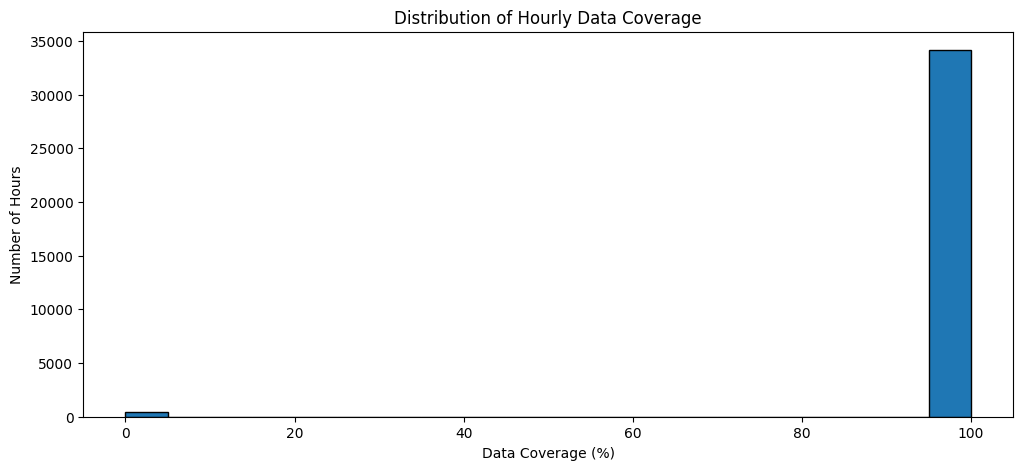

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    hourly["coverage_percent"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Hourly Data Coverage")

plt.xlabel("Data Coverage (%)")

plt.ylabel("Number of Hours")

plt.show()

In [46]:
# Set datetime as index
time_df = clean_df.set_index("datetime").sort_index()

# Generate expected minute-level timestamps
expected_timestamps = pd.date_range(
    start=time_df.index.min(),
    end=time_df.index.max(),
    freq="min"
)

# Find missing timestamps
missing_timestamps = expected_timestamps.difference(
    time_df.index
)

print("Expected timestamps:", len(expected_timestamps))
print("Actual timestamps:", len(time_df))
print("Missing timestamps:", len(missing_timestamps))

Expected timestamps: 2075259
Actual timestamps: 2075259
Missing timestamps: 0


In [47]:
hourly_index = pd.DatetimeIndex(hourly["datetime"])

expected_hours = pd.date_range(
    start=hourly_index.min(),
    end=hourly_index.max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    hourly_index
)

print("Expected hours:", len(expected_hours))
print("Available hours:", len(hourly_index))
print("Missing hours:", len(missing_hours))

Expected hours: 34589
Available hours: 34589
Missing hours: 0


In [48]:
complete_hours = hourly[
    hourly["is_complete"]
].copy()

complete_hours["calculation_difference"] = (
    complete_hours["energy_kwh"]
    - complete_hours["avg_power_kw"]
)

print(
    "Maximum calculation difference:",
    complete_hours["calculation_difference"].abs().max()
)

Maximum calculation difference: 0.0


In [49]:
import sqlite3

NEW_DB_PATH = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "energy_v2.db"
)

conn = sqlite3.connect(NEW_DB_PATH)

print("New database created:", NEW_DB_PATH)

New database created: c:\Users\AshishKaur\OneDrive\Desktop\enery-usage-analyser\data\processed\energy_v2.db


In [50]:
create_table = """
CREATE TABLE IF NOT EXISTS hourly_usage (
    datetime TEXT PRIMARY KEY,
    avg_power_kw REAL,
    energy_kwh REAL,
    observed_energy_kwh REAL,
    valid_minutes INTEGER,
    total_records INTEGER,
    coverage_percent REAL,
    is_complete INTEGER,
    hour INTEGER,
    weekday TEXT,
    month INTEGER,
    year INTEGER,
    is_weekend INTEGER
);
"""

conn.execute(create_table)

conn.commit()

In [51]:
database_df = hourly[
    [
        "datetime",
        "avg_power_kw",
        "energy_kwh",
        "observed_energy_kwh",
        "valid_minutes",
        "total_records",
        "coverage_percent",
        "is_complete",
        "hour",
        "weekday",
        "month",
        "year",
        "is_weekend"
    ]
].copy()

In [52]:
database_df["is_complete"] = (
    database_df["is_complete"].astype(int)
)

database_df["is_weekend"] = (
    database_df["is_weekend"].astype(int)
)

In [53]:
database_df["datetime"] = (
    database_df["datetime"].dt.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
)

In [54]:
database_df.to_sql(
    "hourly_usage",
    conn,
    if_exists="append",
    index=False
)

conn.commit()

print("Hourly records successfully inserted!")

Hourly records successfully inserted!


In [55]:
database_check = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS total_records,
        MIN(datetime) AS first_timestamp,
        MAX(datetime) AS last_timestamp,
        AVG(coverage_percent) AS average_coverage,
        SUM(is_complete) AS complete_hours
    FROM hourly_usage
    """,
    conn
)

display(database_check)

,total_records,first_timestamp,last_timestamp,average_coverage,complete_hours
0,34589,2006-12-16 17:00:00,2010-11-26 21:00:00,98.744302,34085


In [56]:
schema = pd.read_sql_query(
    "PRAGMA table_info(hourly_usage)",
    conn
)

display(schema)

,cid,name,type,notnull,dflt_value,pk
0,0,datetime,TEXT,0,None,1
1,1,avg_power_kw,REAL,0,None,0
2,2,energy_kwh,REAL,0,None,0
3,3,observed_energy_kwh,REAL,0,None,0
4,4,valid_minutes,INTEGER,0,None,0
5,5,total_records,INTEGER,0,None,0
6,6,coverage_percent,REAL,0,None,0
7,7,is_complete,INTEGER,0,None,0
8,8,hour,INTEGER,0,None,0
9,9,weekday,TEXT,0,None,0


In [57]:
conn.close()

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [60]:
DB_PATH = PROJECT_ROOT / "data" / "processed" / "energy_v2.db"

conn = sqlite3.connect(DB_PATH)

hourly_df = pd.read_sql_query(
    "SELECT * FROM hourly_usage",
    conn
)

hourly_df.head()

,datetime,avg_power_kw,energy_kwh,observed_energy_kwh,valid_minutes,total_records,coverage_percent,is_complete,hour,weekday,month,year,is_weekend
0,2006-12-16 17:00:00,4.222889,NaN,2.533733,36,36,60.0,0,17,Saturday,12,2006,1
1,2006-12-16 18:00:00,3.632200,3.632200,3.632200,60,60,100.0,1,18,Saturday,12,2006,1
2,2006-12-16 19:00:00,3.400233,3.400233,3.400233,60,60,100.0,1,19,Saturday,12,2006,1
3,2006-12-16 20:00:00,3.268567,3.268567,3.268567,60,60,100.0,1,20,Saturday,12,2006,1
4,2006-12-16 21:00:00,3.056467,3.056467,3.056467,60,60,100.0,1,21,Saturday,12,2006,1


In [61]:
print("Dataset shape:", hourly_df.shape)

print("\nColumn names:")
print(hourly_df.columns.tolist())

print("\nDataset information:")
hourly_df.info()

print("\nStatistical summary:")
display(hourly_df.describe())

Dataset shape: (34589, 13)

Column names:
['datetime', 'avg_power_kw', 'energy_kwh', 'observed_energy_kwh', 'valid_minutes', 'total_records', 'coverage_percent', 'is_complete', 'hour', 'weekday', 'month', 'year', 'is_weekend']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 34589 entries, 0 to 34588
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   datetime             34589 non-null  str    
 1   avg_power_kw         34168 non-null  float64
 2   energy_kwh           34085 non-null  float64
 3   observed_energy_kwh  34589 non-null  float64
 4   valid_minutes        34589 non-null  int64  
 5   total_records        34589 non-null  int64  
 6   coverage_percent     34589 non-null  float64
 7   is_complete          34589 non-null  int64  
 8   hour                 34589 non-null  int64  
 9   weekday              34589 non-null  str    
 10  month                34589 non-null  int64  
 11

,avg_power_kw,energy_kwh,observed_energy_kwh,valid_minutes,total_records,coverage_percent,is_complete,hour,month,year,is_weekend
count,34168.000000,34085.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000
mean,1.091728,1.090361,1.077908,59.246581,59.997658,98.744302,0.985429,11.501084,6.450548,2008.436613,0.285380
std,0.897619,0.896738,0.899925,6.636243,0.332539,11.060405,0.119830,6.922394,3.415879,1.128731,0.451602
min,0.124000,0.124000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,0.000000
25%,0.341925,0.341700,0.336967,60.000000,60.000000,100.000000,1.000000,6.000000,3.000000,2007.000000,0.000000
50%,0.802850,0.801833,0.782467,60.000000,60.000000,100.000000,1.000000,12.000000,6.000000,2008.000000,0.000000
75%,1.579342,1.578133,1.570100,60.000000,60.000000,100.000000,1.000000,18.000000,9.000000,2009.000000,1.000000
max,6.560533,6.560533,6.560533,60.000000,60.000000,100.000000,1.000000,23.000000,12.000000,2010.000000,1.000000


In [62]:
print("Duplicate timestamps:",
      hourly_df["datetime"].duplicated().sum())

print("\nMissing values:")
display(hourly_df.isnull().sum())

print("\nComplete vs incomplete hours:")
display(hourly_df["is_complete"].value_counts())

Duplicate timestamps: 0

Missing values:


datetime                 0
avg_power_kw           421
energy_kwh             504
observed_energy_kwh      0
valid_minutes            0
total_records            0
coverage_percent         0
is_complete              0
hour                     0
weekday                  0
month                    0
year                     0
is_weekend               0
dtype: int64


Complete vs incomplete hours:


is_complete
1    34085
0      504
Name: count, dtype: int64

In [63]:
# Keep only complete hourly observations
complete_df = hourly_df[
    hourly_df["is_complete"] == 1
].copy()

# Convert datetime from string to actual datetime format
complete_df["datetime"] = pd.to_datetime(
    complete_df["datetime"]
)

# Select the energy consumption column
energy = complete_df["energy_kwh"]

print("Complete observations:", len(complete_df))
print("Missing energy values:", energy.isnull().sum())

Complete observations: 34085
Missing energy values: 0


In [64]:
mean_energy = energy.mean()
median_energy = energy.median()
mode_energy = energy.mode()[0]
std_energy = energy.std()
variance_energy = energy.var()

print("MEAN:", mean_energy)
print("MEDIAN:", median_energy)
print("MODE:", mode_energy)
print("STANDARD DEVIATION:", std_energy)
print("VARIANCE:", variance_energy)

MEAN: 1.0903613036037358
MEDIAN: 0.8018333333333333
MODE: 0.29786666666666667
STANDARD DEVIATION: 0.8967375663749121
VARIANCE: 0.804138262948


In [65]:
Q1 = energy.quantile(0.25)
Q2 = energy.quantile(0.50)
Q3 = energy.quantile(0.75)

IQR = Q3 - Q1

print("Q1 (25th percentile):", Q1)
print("Q2 (50th percentile):", Q2)
print("Q3 (75th percentile):", Q3)
print("Interquartile Range:", IQR)

Q1 (25th percentile): 0.3417
Q2 (50th percentile): 0.8018333333333333
Q3 (75th percentile): 1.5781333333333334
Interquartile Range: 1.2364333333333333


In [66]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = complete_df[
    (complete_df["energy_kwh"] < lower_bound) |
    (complete_df["energy_kwh"] > upper_bound)
]

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

print("Number of potential outliers:", len(outliers))

print("\nHighest consumption observations:")
display(
    outliers.sort_values(
        by="energy_kwh",
        ascending=False
    ).head(10)
)

Lower boundary: -1.51295
Upper boundary: 3.432783333333333
Number of potential outliers: 728

Highest consumption observations:


,datetime,avg_power_kw,energy_kwh,observed_energy_kwh,valid_minutes,total_records,coverage_percent,is_complete,hour,weekday,month,year,is_weekend
16993,2008-11-23 18:00:00,6.560533,6.560533,6.560533,60,60,100.0,1,18,Sunday,11,2008,1
18291,2009-01-16 20:00:00,6.519633,6.519633,6.519633,60,60,100.0,1,20,Friday,1,2009,0
9914,2008-02-02 19:00:00,6.496033,6.496033,6.496033,60,60,100.0,1,19,Saturday,2,2008,1
8930,2007-12-23 19:00:00,6.488000,6.488000,6.488000,60,60,100.0,1,19,Sunday,12,2007,1
1636,2007-02-22 21:00:00,6.363867,6.363867,6.363867,60,60,100.0,1,21,Thursday,2,2007,0
9048,2007-12-28 17:00:00,6.333667,6.333667,6.333667,60,60,100.0,1,17,Friday,12,2007,0
16995,2008-11-23 20:00:00,6.310567,6.310567,6.310567,60,60,100.0,1,20,Sunday,11,2008,1
867,2007-01-21 20:00:00,6.076567,6.076567,6.076567,60,60,100.0,1,20,Sunday,1,2007,1
9746,2008-01-26 19:00:00,6.013800,6.013800,6.013800,60,60,100.0,1,19,Saturday,1,2008,1
17163,2008-11-30 20:00:00,5.930500,5.930500,5.930500,60,60,100.0,1,20,Sunday,11,2008,1


In [67]:
statistics_report = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Mode",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "25th Percentile",
        "75th Percentile",
        "IQR"
    ],

    "Energy (kWh)": [
        energy.mean(),
        energy.median(),
        energy.mode()[0],
        energy.std(),
        energy.var(),
        energy.min(),
        energy.max(),
        Q1,
        Q3,
        IQR
    ]
})

display(statistics_report.round(4))

,Metric,Energy (kWh)
0,Mean,1.0904
1,Median,0.8018
2,Mode,0.2979
3,Standard Deviation,0.8967
4,Variance,0.8041
5,Minimum,0.1240
6,Maximum,6.5605
7,25th Percentile,0.3417
8,75th Percentile,1.5781
9,IQR,1.2364


In [68]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_pattern = (
    complete_df.groupby("weekday")["energy_kwh"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

weekday_pattern.columns = [
    "Weekday",
    "Average_Energy_kWh"
]

display(weekday_pattern)

,Weekday,Average_Energy_kWh
0,Monday,0.998273
1,Tuesday,1.069425
2,Wednesday,1.080833
3,Thursday,0.980636
4,Friday,1.043325
5,Saturday,1.246538
6,Sunday,1.218419


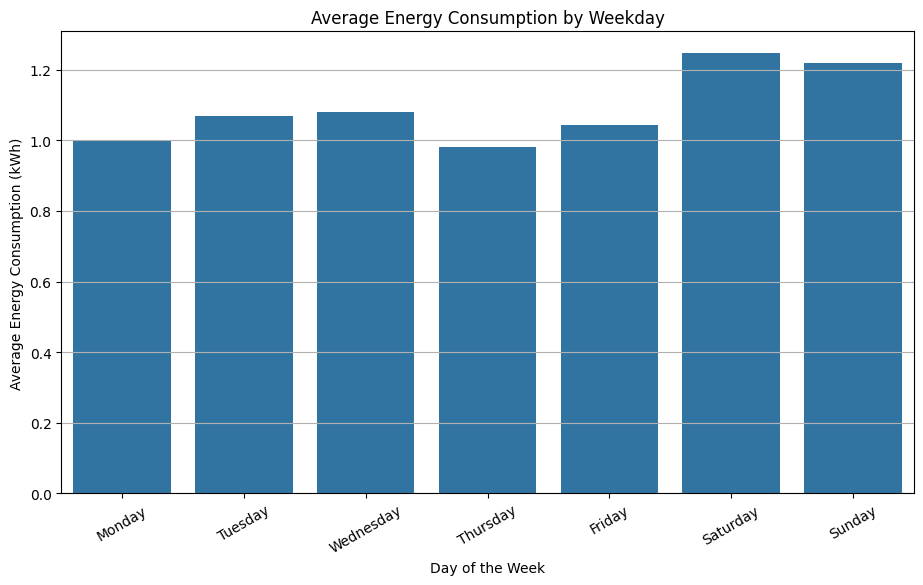

In [69]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=weekday_pattern,
    x="Weekday",
    y="Average_Energy_kWh"
)

plt.title("Average Energy Consumption by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Energy Consumption (kWh)")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()